### Code for making figures 3 and 5 in Nilssen et al 2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.ndimage import gaussian_filter1d

In [2]:
mbs_accum = pd.read_csv("data/mbs_accum_record.csv")

In [3]:
mbs_accum

,Depth,Horizon_Type,Year,depth_corrected,layer_thickness,fitted_densities,IE_layer_thickness,IE_depth,age,IE_accum_nye_1978,IE_accum_SR2.59,IE_accum_apres
0,0.588,1,2017,0.2940,0.588,443.839763,0.284600,0.141457,0,0.284620,0.284600,0.284600
1,1.044,1,2016,0.8160,0.456,452.858835,0.225195,0.396700,1,0.225240,0.225253,0.225253
2,1.717,1,2015,1.3805,0.673,462.125156,0.339161,0.678355,2,0.339277,0.339336,0.339336
3,2.024,1,2014,1.8705,0.307,469.783619,0.157278,0.927353,3,0.157351,0.157400,0.157400
4,2.444,1,2013,2.2340,0.420,475.246751,0.217670,1.114665,4,0.217793,0.217896,0.217896
...,...,...,...,...,...,...,...,...,...,...,...,...
1140,293.732,1,877,293.5410,0.382,916.899546,0.381958,271.609468,1140,0.442755,0.513151,0.513151
1141,294.013,1,876,293.8725,0.281,916.900567,0.280970,271.940932,1141,0.325755,0.377573,0.377573
1142,294.319,1,875,294.1660,0.306,916.901462,0.305967,272.234400,1142,0.354798,0.411272,0.411272
1143,294.501,1,874,294.4100,0.182,916.902200,0.181981,272.478374,1143,0.211054,0.244677,0.244677


In [4]:
#  a function that calculates the mean between two points in the time series
# includes upper and lower limites

def mean_between(df, accum_col, lower_lim, upper_lim):
    return np.mean(df[(df["Year"]>=lower_lim) & (df["Year"]<=upper_lim)][accum_col])

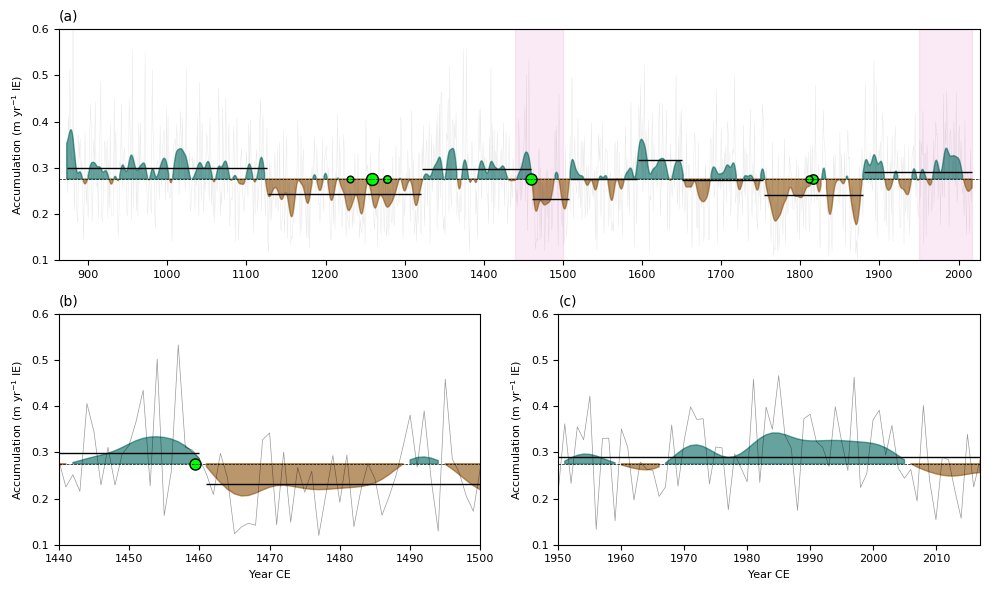

In [5]:
# fig for manuscript

timestamp = datetime.now().strftime('%Y%m%d_%H%M')

acc_col = "IE_accum_apres"
accum = mbs_accum[acc_col]
mean_accum = np.mean(accum)
year = mbs_accum["Year"]

high_colour = "#01665E"
low_colour = "#8C510A"


sigma_value = 3
gfilter = gaussian_filter1d(accum, sigma=sigma_value)

volcano_av_sulfate = {1258.3 : 73.4,
                      1459.4 : 63.6,
                      1816.3: 45.8,
                      1277.5: 29.9,
                      1810.3 : 25.4,
                      1230.8: 23.1}
# average sulfate values from Sigl et al 2014

cp_list = [873, 1127, 1322, 1461, 1509, 1595, 1651, 1754, 1880, 2018]
# these are CPs when we go from depth up. plus start and end points


fig, axs = plt.subplot_mosaic("""
AA
BC
""",
                             figsize=(10,6))
ax1= axs["A"]
ax2 = axs["B"]
ax3 = axs["C"]

b_start = 1440
b_end = 1500

c_start = 1950
c_end = 2017

ax1.axvspan(b_start, b_end, color='tab:pink', alpha=0.15)
ax1.axvspan(c_start, c_end, color='tab:pink', alpha=0.15)


ax1.plot(year, accum, label = "IE accum", color= 'black', alpha=0.1, linewidth=0.3)
ax1.axhline(y=mean_accum, color = 'black', linewidth=0.5, linestyle='--')
ax1.fill_between(year, gfilter, mean_accum, where=(gfilter > mean_accum), alpha=0.6, color=high_colour)
ax1.fill_between(year, mean_accum, gfilter,  where=(gfilter < mean_accum), alpha=0.6, color=low_colour)
for year_, sulfate in volcano_av_sulfate.items():
    ax1.scatter(x=year_, y=mean_accum, s=sulfate, color = "lime", edgecolor="black")


for i in range(len(cp_list) - 1):

    start = cp_list[i] # includes start of regime
    end = cp_list[i+1] - 1 # doesn;t include end year

    ax1.hlines(
        y=mean_between(mbs_accum, acc_col, start, end),
        xmin=start,
        xmax=end,
        color="black",
        linewidth=1
    )


ax1.set_ylabel('Accumulation (m yr$^{-1}$ IE)', size=8)
ax1.set_xticks(ticks=np.arange(800, 2100, 100.0))
ax1.tick_params(axis='both', which='major', labelsize=8)
#ax.set_title(acc_col)
ax1.set_xlim(863, 2027)
ax1.set_ylim(0.1,0.6)
ax1.set_title("(a)",  loc='left', fontsize='medium')

sigma_value = 3
gfilter = gaussian_filter1d(accum, sigma=sigma_value)

ax2.plot(year, accum, label = "IE accum", color= 'black', alpha=0.4, linewidth=0.5)
ax2.axhline(y=mean_accum, color = 'black', linewidth=0.5, linestyle='--')
ax2.fill_between(year, gfilter, mean_accum, where=(gfilter > mean_accum), alpha=0.6, color=high_colour)
ax2.fill_between(year, mean_accum, gfilter,  where=(gfilter < mean_accum), alpha=0.6, color=low_colour)
for year_, sulfate in volcano_av_sulfate.items():
    ax2.scatter(x=year_, y=mean_accum, s=sulfate, color = "lime", edgecolor="black")
for i in range(len(cp_list) - 1):

    start = cp_list[i] # includes start of regime
    end = cp_list[i+1] - 1 # doesn;t include end year

    ax2.hlines(
        y=mean_between(mbs_accum, acc_col, start, end),
        xmin=start,
        xmax=end,
        color="black",
        linewidth=1
    )


ax2.set_ylabel('Accumulation (m yr$^{-1}$ IE)', size=8)
ax2.set_xticks(ticks=np.arange(800, 2100, 10.0))
ax2.tick_params(axis='both', which='major', labelsize=8)
#ax.set_title(acc_col)
ax2.set_ylim(0.1, 0.6)
ax2.set_xlim(b_start, b_end)
ax2.set_xlabel("Year CE", size=8)
ax2.set_title("(b)",  loc='left', fontsize='medium')

ax3.plot(year, accum, label = "IE accum", color= 'black', alpha=0.4, linewidth=0.5)
ax3.axhline(y=mean_accum, color = 'black', linewidth=0.5, linestyle='--')
ax3.fill_between(year, gfilter, mean_accum, where=(gfilter > mean_accum), alpha=0.6, color=high_colour)
ax3.fill_between(year, mean_accum, gfilter,  where=(gfilter < mean_accum), alpha=0.6, color=low_colour)
for i in range(len(cp_list) - 1):

    start = cp_list[i] # includes start of regime
    end = cp_list[i+1] - 1 # doesn;t include end year

    ax3.hlines(
        y=mean_between(mbs_accum, acc_col, start, end),
        xmin=start,
        xmax=end,
        color="black",
        linewidth=1
    )
ax3.set_ylabel('Accumulation (m yr$^{-1}$ IE)', size=8)
ax3.set_xticks(ticks=np.arange(800, 2100, 10.0))
ax3.tick_params(axis='both', which='major', labelsize=8)
#ax.set_title(acc_col)
ax3.set_ylim(0.1,0.6)
ax3.set_xlim(c_start, c_end)
ax3.set_xlabel("Year CE", size=8)
ax3.set_title("(c)",  loc='left', fontsize='medium')
plt.tight_layout()
# plt.savefig(f'figs/mbs_accum_record_{timestamp}.pdf')

In [6]:
# read in DSS accum dataset
DSS_dset = pd.read_csv('data/DSS_2k_winter_centred.csv')
# DSS_dset = DSS_dset[DSS_dset["Year"] > 872]
DSS_accum = DSS_dset[["Year", "Accumulation rate (IE m/y)"]]
DSS_accum=DSS_accum.rename(columns={"Accumulation rate (IE m/y)": "DSS_accum"})
DSS_accum

,Year,DSS_accum
0,2016,0.734644
1,2015,0.694271
2,2014,0.655290
3,2013,0.667699
4,2012,0.630642
...,...,...
2023,-7,0.627574
2024,-8,0.741743
2025,-9,1.032600
2026,-10,0.654411


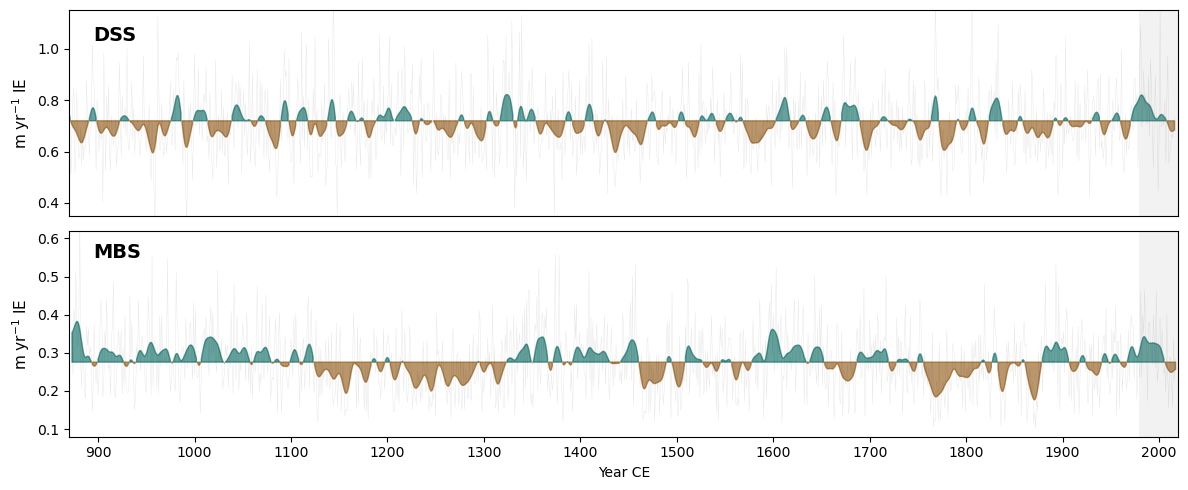

In [11]:
timestamp = datetime.now().strftime('%Y%m%d_%H%M')
high_colour = "#01665E"
low_colour = "#8C510A"
alpha = 0.1
linewidth = 0.3

fig, (ax1, ax2) = plt.subplots(
    nrows=2,
    sharex=True,
    figsize=(12,5)
    # gridspec_kw={'hspace': 0}
)

sigma_value = 3


# DSS
accum = DSS_accum["DSS_accum"]
year = DSS_accum["Year"]
mean_accum = np.mean(accum)
label= "DSS"



gfilter = gaussian_filter1d(accum, sigma=sigma_value)

ax1.plot(year, accum, label = "IE accum", color= 'black', alpha=alpha, linewidth=linewidth)
# ax1.axhline(y=mean_accum, xmin = np.min(year), xmax = np.max(year), color = 'black', linewidth=1, linestyle='--')
ax1.fill_between(year, gfilter, mean_accum, where=(gfilter > mean_accum), alpha=0.6, color=high_colour)
ax1.fill_between(year, mean_accum, gfilter,  where=(gfilter < mean_accum), alpha=0.6, color=low_colour)
ax1.text(x=895, y=1.03, s="DSS", size=14, weight="bold")
ax1.tick_params(axis="x", bottom=False)
ax1.set_ylim(0.35, 1.15)
ax1.set_ylabel('m yr$^{-1}$ IE', size=11)


# MBS
accum = mbs_accum["IE_accum_apres"]
year = mbs_accum["Year"]
mean_accum = np.mean(accum)
label = "MBS"

gfilter = gaussian_filter1d(accum, sigma=sigma_value)

ax2.plot(year, accum, label = "IE accum", color= 'black', alpha=alpha, linewidth=linewidth)
# ax2.axhline(y=mean_accum, xmin = np.min(year), xmax = np.max(year), color = 'black', linewidth=1, linestyle='--')
ax2.fill_between(year, gfilter, mean_accum, where=(gfilter > mean_accum), alpha=0.6, color=high_colour)
ax2.fill_between(year, mean_accum, gfilter,  where=(gfilter < mean_accum), alpha=0.6, color=low_colour)
ax2.text(x=895, y=0.55, s="MBS", size=14, weight="bold")
ax2.set_xticks(ticks=np.arange(800, 2100, 100.0))
ax2.set_xlabel("Year CE")

ax2.set_xlim(870, 2020)

# for ax in [ax1, ax2]:
    # ax.axvspan(1979, 2020, color='g', alpha=0.05, lw=0)
    # ax.spines['top'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    # ax.tick_params(axis="x", bottom=False)
ax2.tick_params(axis="x", bottom=True)
ax2.set_ylim(0.08, 0.62)
ax2.set_ylabel('m yr$^{-1}$ IE', size=11)

for ax in [ax1, ax2]:
    ax.axvspan(1979, 2020, color='grey', alpha=0.1, lw=0)


fig.tight_layout()
# plt.savefig(f'figs/MBS_DSS_accum_{timestamp}.pdf')